# Catégorisation automatique des dépenses

Ce notebook documente le modèle qui propose une catégorie à partir du libellé d'une dépense dans l'application Mes Dépenses : origine des données, nettoyage, exploration, comparaison de modèles, évaluation et limites.

Il s'appuie sur les scripts du dossier `ml/`, qui sont ceux réellement utilisés pour produire le modèle servi par l'API :

| Script | Rôle |
|---|---|
| `ml/vocabulary.py` | Libellés de base, rédigés à la main |
| `ml/build_dataset.py` | Génération des variantes |
| `ml/prepare.py` | Nettoyage |
| `ml/train.py` | Comparaison, évaluation, enregistrement du modèle |

In [1]:
import os, sys, pathlib

# Le notebook se place à la racine de l'API, quel que soit le dossier d'où il est lancé.
ROOT = pathlib.Path.cwd()
while not (ROOT / "app").is_dir():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone

from app.services import categorizer
from ml import build_dataset, prepare, train

VERT, VERT_CLAIR, GRIS, TEXTE = "#0F5D4A", "#B9D3CB", "#5B6661", "#16201C"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#CFD5D1", "axes.labelcolor": GRIS, "xtick.color": GRIS, "ytick.color": GRIS,
    "text.color": TEXTE, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
})
pd.set_option("display.max_colwidth", 60)

## 1. Origine des données

**Le jeu de données est synthétique.** Aucun historique réel de dépenses n'était disponible au démarrage du projet. Les données ont donc été construites en deux temps :

1. 657 libellés de base, de 59 à 85 par catégorie, rédigés à la main pour refléter des dépenses courantes à Abidjan (`ml/vocabulary.py`). Une première version en comptait 450 ; le vocabulaire a ensuite été enrichi ;
2. pour chaque libellé de base, 14 variantes générées : ajout d'un lieu ou d'une précision, abréviation, majuscules, accents oubliés, faute de frappe (`ml/build_dataset.py`).

La colonne `groupe` identifie le libellé de base dont chaque ligne dérive. Elle sert plus loin à évaluer le modèle correctement.

Conséquence à garder en tête : les performances mesurées décrivent le comportement du modèle sur ce vocabulaire. Elles devront être confirmées sur des libellés réels, que l'application collecte au fil de l'usage (section 9).

In [2]:
brut = pd.read_csv(build_dataset.RAW_PATH)
print(f"{len(brut)} libellés bruts, {brut['groupe'].nunique()} libellés de base, {brut['categorie'].nunique()} catégories")
brut[brut["groupe"] == "Transport-00"].head(8)

9855 libellés bruts, 657 libellés de base, 10 catégories


,libelle,categorie,groupe
1909,Gbaka Marcory,Transport,Transport-00
2135,Gbaka,Transport,Transport-00
2989,Gbaka Attécoubé,Transport,Transport-00
3132,gbaka plateau,Transport,Transport-00
3134,Gbaka pr les entfs,Transport,Transport-00
3564,Gbaka Pot-Bouët,Transport,Transport-00
4929,Gbaka,Transport,Transport-00
5603,GBAKA,Transport,Transport-00


## 2. Nettoyage

Le nettoyage applique quatre étapes (`ml/prepare.py`) :

1. **normalisation** : minuscules, suppression des accents et de la ponctuation. La fonction est celle que l'API applique avant de prédire, ce qui garantit que le modèle voit le même texte à l'entraînement et en service ;
2. suppression des libellés **trop courts** (moins de 3 caractères) ;
3. suppression des **doublons** après normalisation ;
4. suppression des libellés **contradictoires**, c'est-à-dire le même texte rangé dans deux catégories.

In [3]:
propre, bilan = prepare.clean(brut)
display(pd.Series(bilan, name="lignes").to_frame())
propre.sample(6, random_state=3)

,lignes
lignes_brutes,9855
trop_courts,0
doublons,3094
contradictoires,0
lignes_propres,6761


,libelle,texte,categorie,groupe
6202,bibliotheque 2e fois,bibliotheque 2e fois,Éducation,Éducation-44
433,Frais participation deuil novembre,frais participation deuil novembre,Autres,Autres-55
4483,frais courses supermarché,frais courses supermarche,Alimentation,Alimentation-15
2850,frais dde carte bancaire,frais dde carte bancaire,Factures,Factures-30
3955,Trajet aeroport Adjame novembre,trajet aeroport adjame novembre,Transport,Transport-55
4967,Frais de livraison fin du mois,frais de livraison fin du mois,Transport,Transport-62


Près d'un tiers des lignes disparaît à l'étape des doublons. C'est attendu : beaucoup de variantes ne diffèrent que par la casse ou les accents, que la normalisation efface.

## 3. Exploration

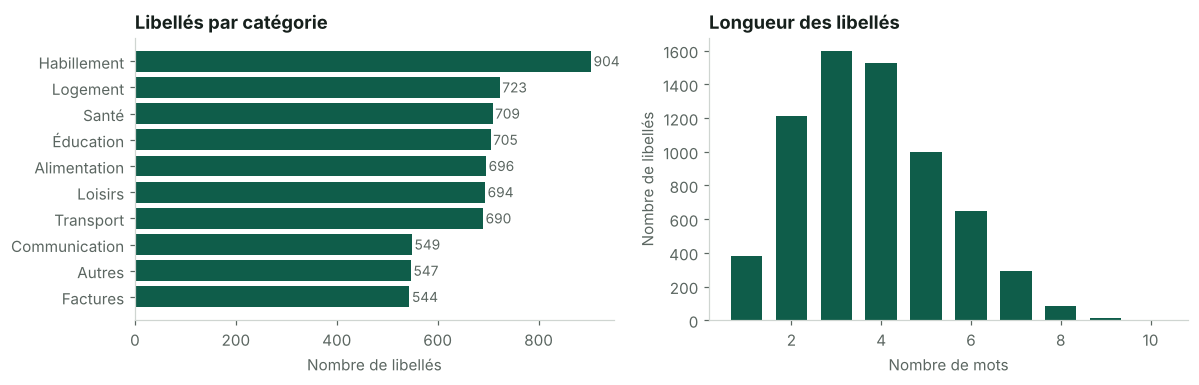

Médiane : 4 mots. Écart entre la catégorie la plus et la moins représentée : 1.66


In [4]:
effectifs = propre["categorie"].value_counts().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].barh(effectifs.index, effectifs.values, color=VERT)
for y, valeur in enumerate(effectifs.values):
    axes[0].text(valeur + 5, y, str(valeur), va="center", fontsize=9, color=GRIS)
axes[0].set_title("Libellés par catégorie")
axes[0].set_xlabel("Nombre de libellés")

longueurs = propre["texte"].str.split().str.len()
compte = longueurs.value_counts().sort_index()
axes[1].bar(compte.index, compte.values, color=VERT, width=0.7)
axes[1].set_title("Longueur des libellés")
axes[1].set_xlabel("Nombre de mots")
axes[1].set_ylabel("Nombre de libellés")
plt.tight_layout()
plt.savefig("ml/reports/exploration.png", bbox_inches="tight")
plt.show()
print(f"Médiane : {int(longueurs.median())} mots. Écart entre la catégorie la plus et la moins représentée : {effectifs.max() / effectifs.min():.2f}")

Deux constats orientent la suite :

- les classes sont **modérément déséquilibrées** : Habillement compte 1,7 fois plus de libellés que Factures. L'écart reste assez faible pour se passer de rééquilibrage, mais il justifie de suivre le F1 macro, qui donne le même poids à chaque catégorie, en plus de l'exactitude ;
- les libellés sont **très courts** (quatre mots en médiane). Le modèle dispose de peu de contexte : tout repose sur le vocabulaire. C'est ce qui justifie de tester des n-grammes de caractères, plus tolérants aux fautes et aux abréviations que les mots entiers.

## 4. Protocole d'évaluation

La manière de découper les données change complètement le résultat. Trois mesures sont calculées, de la plus optimiste à la plus exigeante.

| Mesure | Principe | Ce qu'elle dit |
|---|---|---|
| Découpage aléatoire | 20 % des lignes tirées au hasard | **Optimiste.** Les variantes d'un même libellé se retrouvent des deux côtés : le modèle a presque déjà vu les réponses |
| Découpage par groupes | 20 % des libellés de base mis de côté avec toutes leurs variantes | **Pessimiste.** Le modèle est interrogé sur des mots qu'il n'a jamais rencontrés |
| Jeu manuel | 120 libellés rédigés séparément, sans passer par le générateur | **La plus proche de l'usage.** Formulations nouvelles, vocabulaire en partie connu |

La comparaison des modèles se fait par validation croisée à 5 plis **par groupes**, sur la partie entraînement uniquement. Le jeu manuel ne sert qu'à l'évaluation finale : aucun réglage n'a été fait à partir de ses erreurs.

Deux limites du jeu manuel doivent être dites :

- il a été rédigé par la même personne que la première version du vocabulaire. Il reste donc plus facile que des libellés saisis par de vrais utilisateurs ;
- lors de l'enrichissement du vocabulaire, sept des libellés ajoutés recoupent directement des lignes de ce jeu (par exemple « Séance de kiné », « Peintre », « Impôt sur le revenu »). Le score obtenu sur le jeu manuel est donc légèrement favorable. La mesure par groupes, elle, n'est pas touchée par ce recoupement : c'est sur elle qu'il faut juger l'effet de l'enrichissement.

In [5]:
rapport = train.run(save=False)
donnees = pd.read_csv(train.CLEAN_PATH)
entrainement, test = train.split_by_group(donnees)
manuel = train.load_manual()
print(f"Entraînement : {len(entrainement)} lignes ({entrainement['groupe'].nunique()} libellés de base)")
print(f"Test par groupes : {len(test)} lignes ({test['groupe'].nunique()} libellés de base)")
print(f"Jeu manuel : {len(manuel)} lignes")

Entraînement : 5410 lignes (526 libellés de base)
Test par groupes : 1351 lignes (131 libellés de base)
Jeu manuel : 120 lignes


## 5. Référence : les règles par mots-clés

Avant tout apprentissage, l'API utilisait une liste de mots-clés par catégorie. C'est le point de comparaison : un modèle n'a d'intérêt que s'il fait mieux.

In [6]:
pd.DataFrame(rapport["regles"]).T.rename(index={"test": "Test par groupes", "test_manuel": "Jeu manuel"})

,exactitude,f1_macro
Test par groupes,0.2998,0.3383
Jeu manuel,0.5583,0.6180


## 6. Comparaison des modèles

Cinq candidats sont comparés. Tous transforment le texte en vecteur TF-IDF, sur des mots, sur des n-grammes de 2 à 5 caractères, ou sur les deux, puis appliquent un classifieur linéaire.

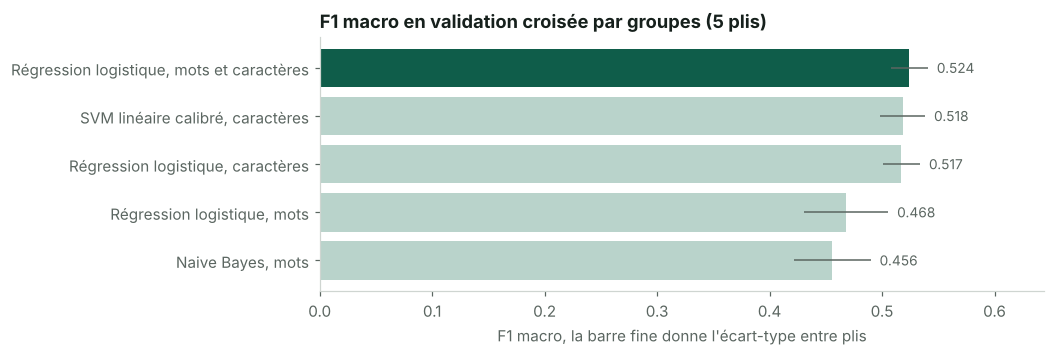

,exactitude,f1_macro,f1_macro_ecart_type
"Régression logistique, mots et caractères",0.5161,0.5243,0.0164
"SVM linéaire calibré, caractères",0.5098,0.5184,0.0198
"Régression logistique, caractères",0.5083,0.5171,0.0166
"Régression logistique, mots",0.4518,0.4678,0.0376
"Naive Bayes, mots",0.4373,0.4557,0.0341


In [7]:
comparaison = pd.DataFrame(rapport["validation_croisee"]).T.sort_values("f1_macro")
fig, ax = plt.subplots(figsize=(8.5, 3))
couleurs = [VERT if nom == rapport["modele_retenu"] else VERT_CLAIR for nom in comparaison.index]
ax.barh(comparaison.index, comparaison["f1_macro"], xerr=comparaison["f1_macro_ecart_type"], color=couleurs,
        error_kw={"ecolor": GRIS, "elinewidth": 1})
for y, (valeur, ecart) in enumerate(zip(comparaison["f1_macro"], comparaison["f1_macro_ecart_type"])):
    ax.text(valeur + ecart + 0.008, y, f"{valeur:.3f}", va="center", fontsize=9, color=GRIS)
ax.set_xlim(0, comparaison["f1_macro"].max() + 0.12)
ax.set_title("F1 macro en validation croisée par groupes (5 plis)")
ax.set_xlabel("F1 macro, la barre fine donne l'écart-type entre plis")
plt.savefig("ml/reports/comparaison.png", bbox_inches="tight")
plt.show()
comparaison.sort_values("f1_macro", ascending=False)

Lecture :

- les modèles à **caractères** dépassent nettement les modèles à **mots** : face à un libellé de base jamais vu, des fragments de mots restent reconnaissables là où le mot entier est inconnu ;
- combiner mots et caractères apporte un léger gain supplémentaire. L'écart avec les autres modèles à caractères est du même ordre que l'écart-type entre plis : il ne faut pas le surinterpréter ;
- les scores sont bas dans l'absolu. C'est l'effet du découpage par groupes, volontairement sévère : la section suivante le met en perspective.

Le modèle retenu est celui dont le F1 macro moyen est le plus élevé.

In [8]:
print("Modèle retenu :", rapport["modele_retenu"])

Modèle retenu : Régression logistique, mots et caractères


## 7. Évaluation du modèle retenu

In [9]:
synthese = pd.DataFrame({
    "Découpage aléatoire (optimiste)": rapport["test_aleatoire"],
    "Test par groupes (pessimiste)": rapport["test"],
    "Jeu manuel": rapport["test_manuel"],
    "Jeu manuel, modèle puis règles (API)": rapport["systeme_complet_test_manuel"],
}).T
synthese["règles seules"] = [None, rapport["regles"]["test"]["exactitude"], rapport["regles"]["test_manuel"]["exactitude"], None]
synthese

,exactitude,f1_macro,règles seules
Découpage aléatoire (optimiste),0.9845,0.9844,NaN
Test par groupes (pessimiste),0.5204,0.5382,0.2998
Jeu manuel,0.9000,0.9010,0.5583
"Jeu manuel, modèle puis règles (API)",0.9083,0.9090,NaN


Ce tableau est le résultat principal.

- **98,5 %** sur le découpage aléatoire : ce chiffre est flatteur et ne doit pas être présenté comme la performance du modèle. Il montre surtout que le modèle a bien appris le vocabulaire qu'on lui a fourni.
- **52 %** sur des libellés de base jamais vus, contre 30 % pour les règles : quand tous les mots importants sont nouveaux, le modèle se trompe encore près d'une fois sur deux. Un classifieur de textes aussi courts généralise mal à un vocabulaire inconnu. Ce score était de 46 % avec les 450 libellés de la première version : élargir le vocabulaire est bien ce qui fait progresser le modèle.
- **90 %** sur le jeu manuel, contre 56 % pour les règles : sur des formulations nouvelles utilisant un vocabulaire en partie connu, le modèle apporte un gain net. Ce chiffre est légèrement favorable, pour la raison donnée à la section 4.
- **91 %** pour le système complet tel que l'API le fait fonctionner (modèle au-dessus du seuil de confiance, sinon règles) : le repli sur les règles rattrape un libellé de plus.

La conclusion pratique : la qualité du modèle dépend avant tout de la **couverture du vocabulaire**. C'est pourquoi l'application enregistre les corrections des utilisateurs (section 9).

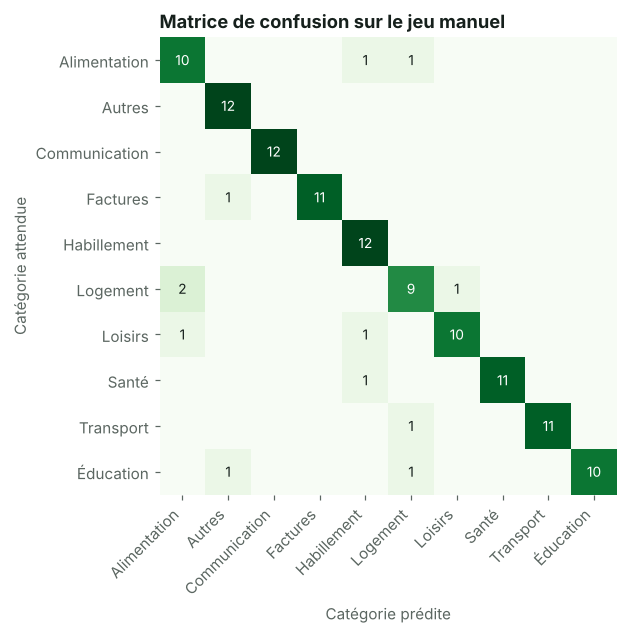

,précision,rappel,F1
Logement,0.75,0.75,0.75
Alimentation,0.77,0.83,0.80
Loisirs,0.91,0.83,0.87
Habillement,0.80,1.00,0.89
Éducation,1.00,0.83,0.91
Autres,0.86,1.00,0.92
Santé,1.00,0.92,0.96
Factures,1.00,0.92,0.96
Transport,1.00,0.92,0.96
Communication,1.00,1.00,1.00


In [10]:
categories = rapport["categories"]
matrice = np.array(rapport["matrice_confusion_test_manuel"])
fig, ax = plt.subplots(figsize=(6.4, 5.4))
ax.imshow(matrice, cmap="Greens", vmin=0, vmax=matrice.max())
ax.set_xticks(range(len(categories)), categories, rotation=45, ha="right")
ax.set_yticks(range(len(categories)), categories)
for i in range(len(categories)):
    for j in range(len(categories)):
        if matrice[i, j]:
            ax.text(j, i, matrice[i, j], ha="center", va="center", fontsize=9,
                    color="white" if matrice[i, j] > matrice.max() / 2 else TEXTE)
ax.set_xlabel("Catégorie prédite")
ax.set_ylabel("Catégorie attendue")
ax.set_title("Matrice de confusion sur le jeu manuel")
for cote in ax.spines.values():
    cote.set_visible(False)
plt.savefig("ml/reports/matrice_confusion.png", bbox_inches="tight")
plt.show()

par_categorie = pd.DataFrame(rapport["par_categorie_test_manuel"]).T.loc[categories, ["precision", "recall", "f1-score"]]
par_categorie.columns = ["précision", "rappel", "F1"]
par_categorie.round(2).sort_values("F1")

Avec 12 libellés par catégorie dans le jeu manuel, chaque erreur déplace le rappel de 8 points : les écarts entre catégories sont indicatifs, pas des classements fiables.

## 8. Analyse des erreurs et de la confiance

In [11]:
pd.DataFrame(rapport["erreurs_test_manuel"])

,libelle,attendu,predit
0,Bidon d'huile 5 litres,Alimentation,Logement
1,Hamburger frites,Alimentation,Habillement
2,Réparation du pot d'échappement,Transport,Logement
3,Nouveau matelas 2 places,Logement,Alimentation
4,Peintre pour le salon,Logement,Loisirs
5,Ampoules LED pour la chambre,Logement,Alimentation
6,Cotisation CNPS trimestre,Factures,Autres
7,Nouvelles lunettes chez l'opticien,Santé,Habillement
8,Achat des fournitures de la rentrée,Éducation,Logement
9,Cantine du mois pour les enfants,Éducation,Autres


Deux causes expliquent la plupart des erreurs :

- **le mot qui porte le sens est absent du vocabulaire d'entraînement** (« hamburger », « pot d'échappement », « karaoké » dans cette tournure). Le modèle se rabat alors sur des fragments de caractères sans rapport. Ce sont les cas que les corrections des utilisateurs viendront combler ;
- **un mot présent dans plusieurs catégories l'emporte sur le reste**. « Soirée au maquis avec les amis » part en Alimentation, vraisemblablement parce que « maquis » figure surtout dans des libellés de repas.

Reste à savoir si le modèle « sait qu'il ne sait pas ». L'API ne retient sa proposition qu'au-dessus d'un seuil de confiance.

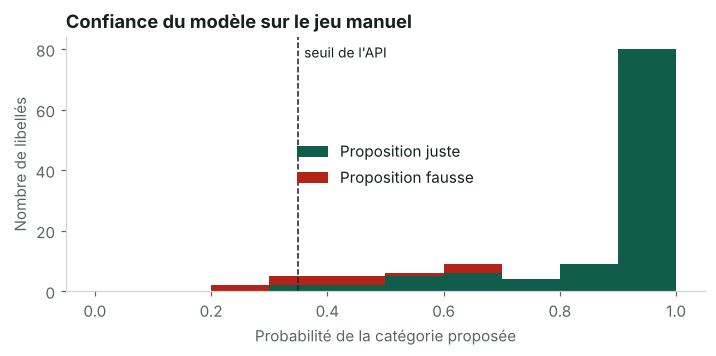

,part des libellés avec proposition,exactitude des propositions
seuil,,
0.00,1.000,0.900
0.25,0.992,0.908
0.35,0.983,0.915
0.50,0.900,0.963
0.65,0.833,0.980
0.80,0.742,1.000


In [12]:
modele = clone(train.candidates()[rapport["modele_retenu"]]).fit(entrainement["texte"], entrainement["categorie"])
probabilites = modele.predict_proba(manuel["texte"])
confiance = probabilites.max(axis=1)
juste = modele.classes_[probabilites.argmax(axis=1)] == manuel["categorie"].values

lignes = []
for seuil in (0.0, 0.25, 0.35, 0.5, 0.65, 0.8):
    retenus = confiance >= seuil
    lignes.append({
        "seuil": seuil,
        "part des libellés avec proposition": retenus.mean(),
        "exactitude des propositions": juste[retenus].mean() if retenus.any() else np.nan,
    })
seuils = pd.DataFrame(lignes).set_index("seuil").round(3)

fig, ax = plt.subplots(figsize=(7.5, 3))
bornes = np.linspace(0, 1, 11)
ax.hist([confiance[juste], confiance[~juste]], bins=bornes, stacked=True, color=[VERT, "#B42318"],
        label=["Proposition juste", "Proposition fausse"])
ax.axvline(categorizer.MIN_MODEL_CONFIDENCE, color=TEXTE, linestyle="--", linewidth=1)
ax.text(categorizer.MIN_MODEL_CONFIDENCE + 0.01, ax.get_ylim()[1] * 0.92, "seuil de l'API", fontsize=9)
ax.set_title("Confiance du modèle sur le jeu manuel")
ax.set_xlabel("Probabilité de la catégorie proposée")
ax.set_ylabel("Nombre de libellés")
ax.legend(frameon=False, loc="center")
plt.savefig("ml/reports/confiance.png", bbox_inches="tight")
plt.show()
seuils

La part de propositions fausses diminue quand la confiance augmente, jusqu'à disparaître au-dessus de 0,8 sur ce jeu : la probabilité renvoyée par le modèle est un signal utile. Monter le seuil rend les propositions plus sûres, mais le modèle se tait plus souvent. Au seuil de 0,35 utilisé par l'API, le modèle propose une catégorie pour 98 % des libellés, et ces propositions sont justes dans 92 % des cas. L'utilisateur voit de toute façon le niveau de confiance et garde la main.

In [13]:
# Mots les plus associés à chaque catégorie, d'après les coefficients de la partie « mots » du modèle.
vectoriseur = modele.named_steps["tfidf"]
classifieur = modele.named_steps["clf"]
if hasattr(vectoriseur, "transformer_list"):
    noms_mots = vectoriseur.transformer_list[0][1].get_feature_names_out()
else:
    noms_mots = vectoriseur.get_feature_names_out()
coefficients = classifieur.coef_[:, : len(noms_mots)]
pd.DataFrame({
    categorie: ", ".join(noms_mots[np.argsort(coefficients[i])[::-1][:8]])
    for i, categorie in enumerate(classifieur.classes_)
}, index=["mots les plus influents"]).T

,mots les plus influents
Alimentation,"et, gingembre, diner en, au, pain, fruits, placali, garba"
Autres,"cadeau, gardien parking, argent, dot, divers, vol, zakat..."
Communication,"pass, credit, unites, sim, sms, megas, carte memoire, ro..."
Factures,"abo, facture, patente, abonnement, passeport, fact, cie,..."
Habillement,"montre, jean, pagne, tenue de, polo, costume, jupe, tenue"
Logement,"gaz, ciment, toiture, loyer, armoire, draps, carrelage, ..."
Loisirs,"bar, jeux, concert, musee, lounge, sortie, crampons, the..."
Santé,"urgences, sante, de sante, depistage, pansements, inject..."
Transport,"voiture, de livraison, moto, taxi, car, peage, uber, bus"
Éducation,"cours, ecole, creche, frais de, coges, udemy, repetiteur..."


Les mots mis en avant sont, pour l'essentiel, ceux qu'un humain choisirait. Une exception instructive : « et » ressort en Alimentation, parce que les libellés de base de cette catégorie contiennent souvent deux produits (« riz et huile », « pain et lait »). C'est un artefact du jeu généré : un signal sans rapport avec le sens, qui peut tirer vers Alimentation un libellé comme « Sirop et paracétamol ». La correction, retirer les mots vides du français, figure dans les pistes ; elle est à mesurer sur un nouveau jeu d'évaluation.

Le modèle a aussi appris ce que les règles ne savent pas faire : dans « Loyer payé par Orange Money », le mot « orange » ne suffit plus à faire basculer la dépense en Communication, car il apparaît dans toutes les catégories comme moyen de paiement.

In [14]:
for texte in ["Loyer payé par Orange Money", "rech orange 1000", "Taxi pour le Plateau", "pharma de garde"]:
    normalise = categorizer.normalize(texte)
    regle = categorizer._suggest_with_rules(normalise)
    proba = modele.predict_proba([normalise])[0]
    print(f"{texte:<30} modèle : {modele.classes_[proba.argmax()]:<14} ({proba.max():.0%})   règles : {regle.category_name if regle else 'aucune'}")

Loyer payé par Orange Money    modèle : Logement       (87%)   règles : Communication
rech orange 1000               modèle : Communication  (98%)   règles : Communication
Taxi pour le Plateau           modèle : Transport      (99%)   règles : Transport
pharma de garde                modèle : Santé          (80%)   règles : aucune


## 9. Limites et suite

**Limites**

- Les données sont synthétiques et rédigées par une seule personne. Les mesures sont probablement plus favorables que ce que donneront de vrais utilisateurs.
- Le modèle ne connaît que les dix catégories par défaut, pas les catégories personnelles.
- Il généralise mal à un vocabulaire inconnu (52 % sur des libellés de base jamais vus).
- Le jeu manuel est petit (120 libellés) et recoupe en partie le vocabulaire enrichi : l'exactitude de 90 % est connue à environ cinq points près, et légèrement favorable.

**Boucle d'amélioration prévue dans l'application**

À chaque dépense, l'API enregistre la catégorie proposée et celle finalement retenue (table `predictions`). Quand l'utilisateur corrige, la paire libellé et catégorie devient un exemple d'entraînement réel :

```
python -m ml.export_corrections
python -m ml.train --corrections ml/data/corrections.csv
```

Cette table donne aussi la mesure qui compte vraiment : le taux de propositions acceptées en usage réel.

**Pistes**

- constituer un nouveau jeu d'évaluation, rédigé par d'autres personnes et jamais consulté pendant la mise au point ;
- retirer les mots vides du français (« et », « de », « pour »), puis mesurer l'effet sur un nouveau jeu d'évaluation ;
- remplacer progressivement les données générées par des libellés réels ;
- tester des représentations pré-entraînées (plongements de phrases multilingues), qui apporteraient une connaissance du sens des mots absents du vocabulaire ;
- utiliser le montant et le jour de la semaine comme variables supplémentaires.